In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('gurgaon_properties_cleaned_v2.csv')

In [5]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,...,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,adani oyster greens,sector 102,1.90,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,...,NaN,NaN,1889.0,1,0,1,1,0,0,0
1,flat,ramprastha city,dwarka expressway,1.30,9027.0,1440.0,Super Built up area 1440(133.78 sq.m.),3.0,3.0,2,...,1440.0,NaN,NaN,0,0,0,0,0,0,0
2,flat,assotech blith,sector 99,0.92,6739.0,1365.0,Super Built up area 1365(126.81 sq.m.),2.0,2.0,3+,...,1365.0,NaN,NaN,0,0,0,0,0,0,56
3,flat,aipl the peaceful homes,sector 70a,2.80,11914.0,2350.0,Super Built up area 2350(218.32 sq.m.)Carpet a...,3.0,4.0,3,...,2350.0,NaN,1322.0,0,1,0,0,0,0,49
4,flat,gls avenue 51,sector 92,0.42,7106.0,591.0,Carpet area: 591 (54.91 sq.m.),2.0,2.0,1,...,NaN,NaN,591.0,1,0,0,1,0,2,42


In [7]:
df.shape

(3816, 23)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3816 entries, 0 to 3815
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   property_type        3816 non-null   object 
 1   society              3815 non-null   object 
 2   sector               3816 non-null   object 
 3   price                3789 non-null   float64
 4   price_per_sqft       3789 non-null   float64
 5   area                 3789 non-null   float64
 6   areaWithType         3816 non-null   object 
 7   bedRoom              3816 non-null   float64
 8   bathroom             3816 non-null   float64
 9   balcony              3816 non-null   object 
 10  floorNum             3797 non-null   float64
 11  facing               2700 non-null   object 
 12  agePossession        3816 non-null   object 
 13  super_built_up_area  1915 non-null   float64
 14  built_up_area        1743 non-null   float64
 15  carpet_area          1948 non-null   f

In [11]:
df.duplicated().sum()

124

In [13]:
df.drop_duplicates(inplace=True)

In [15]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,...,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,adani oyster greens,sector 102,1.90,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,...,NaN,NaN,1889.0,1,0,1,1,0,0,0
1,flat,ramprastha city,dwarka expressway,1.30,9027.0,1440.0,Super Built up area 1440(133.78 sq.m.),3.0,3.0,2,...,1440.0,NaN,NaN,0,0,0,0,0,0,0
2,flat,assotech blith,sector 99,0.92,6739.0,1365.0,Super Built up area 1365(126.81 sq.m.),2.0,2.0,3+,...,1365.0,NaN,NaN,0,0,0,0,0,0,56
3,flat,aipl the peaceful homes,sector 70a,2.80,11914.0,2350.0,Super Built up area 2350(218.32 sq.m.)Carpet a...,3.0,4.0,3,...,2350.0,NaN,1322.0,0,1,0,0,0,0,49
4,flat,gls avenue 51,sector 92,0.42,7106.0,591.0,Carpet area: 591 (54.91 sq.m.),2.0,2.0,1,...,NaN,NaN,591.0,1,0,0,1,0,2,42


property_type

<Axes: xlabel='property_type'>

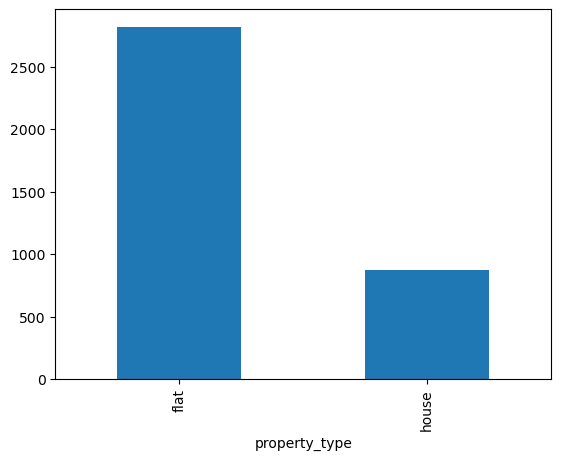

In [17]:
df['property_type'].value_counts().plot(kind='bar',)

In [19]:
df['society'].value_counts().shape

(676,)

In [21]:
df['society'].value_counts()

society
independent                             499
tulip violet                             75
ss the leaf                              73
dlf new town heights                     42
shapoorji pallonji joyville gurugram     42
                                       ... 
cghs hewo apartments                      1
dlf city plot phase 3                     1
conscient one                             1
shapoorji pallonji joyville               1
maruti vihar colony                       1
Name: count, Length: 676, dtype: int64

In [23]:
df[df['society'] != 'independent']['society'].value_counts(normalize=True).cumsum().head(75)

society
tulip violet                            0.023496
ss the leaf                             0.046366
dlf new town heights                    0.059524
shapoorji pallonji joyville gurugram    0.072682
signature global park                   0.083647
                                          ...   
umang winter hills                      0.490288
puri emerald bay                        0.494361
indiabulls enigma                       0.498434
ireo the corridors                      0.502193
mvn athens                              0.505952
Name: proportion, Length: 75, dtype: float64

In [25]:
society_counts = df['society'].value_counts()

# Frequency distribution for societies
frequency_bins = {
    "Very High (>100)": (society_counts > 100).sum(),
    "High (50-100)": ((society_counts >= 50) & (society_counts <= 100)).sum(),
    "Average (10-49)": ((society_counts >= 10) & (society_counts < 50)).sum(),
    "Low (2-9)": ((society_counts > 1) & (society_counts < 10)).sum(),
    "Very Low (1)": (society_counts == 1).sum()
}
frequency_bins

{'Very High (>100)': 1,
 'High (50-100)': 2,
 'Average (10-49)': 92,
 'Low (2-9)': 273,
 'Very Low (1)': 308}

<Axes: xlabel='society'>

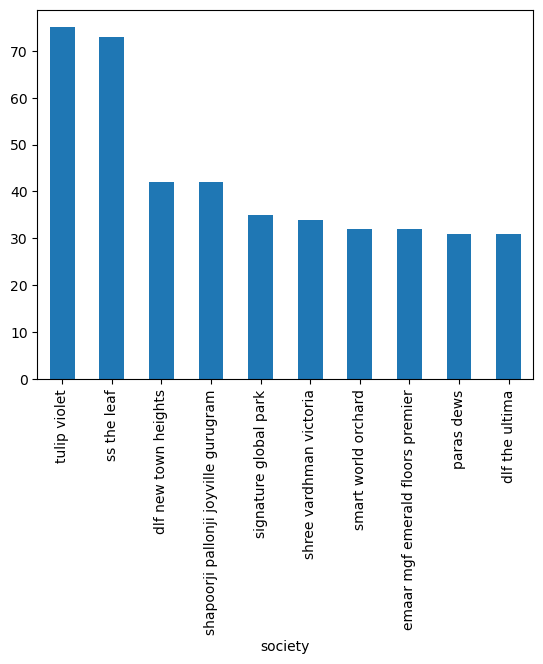

In [27]:
# top 10 socities
df[df['society'] != 'independent']['society'].value_counts().head(10).plot(kind='bar')

In [29]:
df['society'].isnull().sum()

1

In [31]:
df[df['society'].isnull()]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,...,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
782,flat,NaN,sector 78,0.6,3692.0,1625.0,Built Up area: 1625 (150.97 sq.m.),2.0,2.0,0,...,NaN,1625.0,NaN,0,0,0,0,0,0,0


In [33]:
# unique sectors
df['sector'].value_counts().shape

(117,)

<Axes: xlabel='sector'>

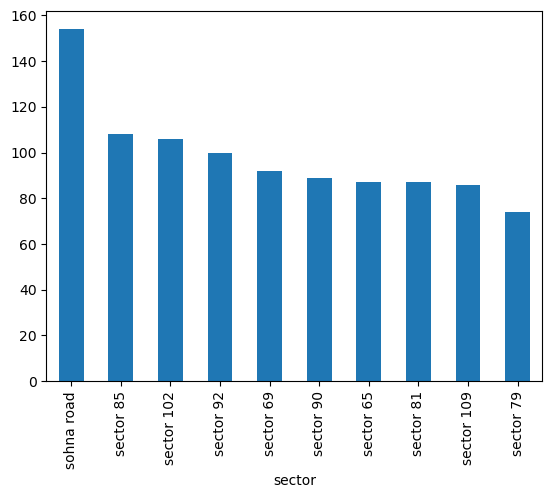

In [35]:
# top 10 sectors
df['sector'].value_counts().head(10).plot(kind='bar')

In [37]:
# Frequency distribution for sectors
sector_counts = df['sector'].value_counts()

sector_frequency_bins = {
    "Very High (>100)": (sector_counts > 100).sum(),
    "High (50-100)": ((sector_counts >= 50) & (sector_counts <= 100)).sum(),
    "Average (10-49)": ((sector_counts >= 10) & (sector_counts < 50)).sum(),
    "Low (2-9)": ((sector_counts > 1) & (sector_counts < 10)).sum(),
    "Very Low (1)": (sector_counts == 1).sum()
}

sector_frequency_bins

{'Very High (>100)': 3,
 'High (50-100)': 26,
 'Average (10-49)': 62,
 'Low (2-9)': 25,
 'Very Low (1)': 1}

In [39]:
df['price'].isnull().sum()

26

In [41]:
df['price'].describe()

count    3666.000000
mean        2.531333
std         2.978771
min         0.075000
25%         0.950000
50%         1.520000
75%         2.750000
max        31.500000
Name: price, dtype: float64

<Axes: xlabel='price', ylabel='Count'>

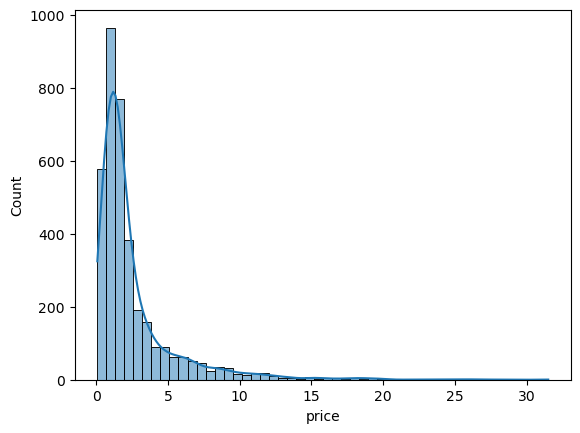

In [43]:
sns.histplot(df['price'], kde=True, bins=50)

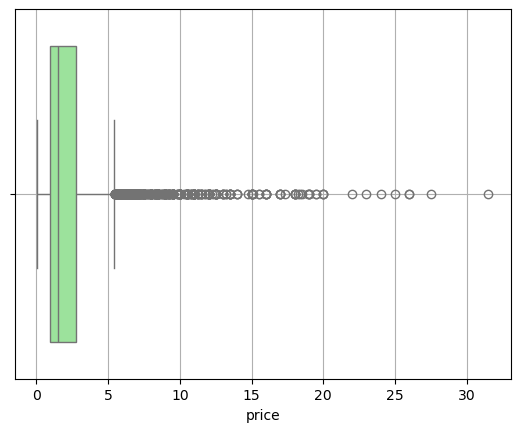

In [45]:
sns.boxplot(x=df['price'], color='lightgreen')
plt.grid()

#Descriptive Statistics:



Count: There are 3,660 non-missing price entries.
Mean Price: The average price is approximately 2.53 crores.
Median Price: The median (or 50th percentile) price is 1.52 crores.
Standard Deviation: The prices have a standard deviation of 2.98, indicating variability in the prices.
Range: Prices range from a minimum of 0.07 crores to a maximum of 31.5 crores.
IQR: The interquartile range (difference between 75th and 25th percentile) is from 0.95 crores to 2.75 crores.

Visualizations:

Distribution: The histogram indicates that most properties are priced in the lower range (below 5 crores), with a few properties going beyond 10 crores.
Box Plot: The box plot showcases the spread of the data and potential outliers. Properties priced above approximately 10 crores might be considered outliers as they lie beyond the upper whisker of the box plot.

Missing Values: There are 17 missing values in the price column.

In [53]:
# Skewness and Kurtosis
skewness = df['price'].skew()
kurtosis = df['price'].kurt()

print(skewness,kurtosis)

3.282051250555869 14.958942854256602


Skewness: The price distribution has a skewness of approximately 3.28, indicating a positive skew. This means that the distribution tail is skewed to the right, which aligns with our observation from the histogram where most properties have prices on the lower end with a few high-priced properties.

Kurtosis: The kurtosis value is approximately 14.93. A kurtosis value greater than 3 indicates a distribution with heavier tails and more outliers compared to a normal distribution.

In [57]:
# Quantile Analysis
quantiles = df['price'].quantile([0.01, 0.05, 0.95, 0.99])

quantiles

0.01     0.25000
0.05     0.37025
0.95     8.50000
0.99    15.24000
Name: price, dtype: float64

Quantile Analysis:

1% Quantile: Only 1% of properties are priced below 0.25 crores.
5% Quantile: 5% of properties are priced below 0.37 crores.
95% Quantile: 95% of properties are priced below 8.5 crores.
99% Quantile: 99% of properties are priced below 15.26 crores, indicating that very few properties are priced above this value.

In [60]:
# Identify potential outliers using IQR method
Q1 = df['price'].describe()['25%']
Q3 = df['price'].describe()['75%']
IQR = Q3 - Q1

IQR

1.8

In [62]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(lower_bound, upper_bound)

-1.7500000000000002 5.45


In [64]:
outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]
outliers.shape

(425, 23)

In [66]:
outliers['price'].describe()

count    425.000000
mean       9.235624
std        4.065259
min        5.460000
25%        6.460000
50%        8.000000
75%       10.750000
max       31.500000
Name: price, dtype: float64

Outliers Analysis (using IQR method):

Based on the IQR method, there are 425 properties considered as outliers.
These outliers have an average price of approximately 9.24 crores.
The range for these outliers is from 5.46 crores to 31.5 crores

<Axes: xlabel='price'>

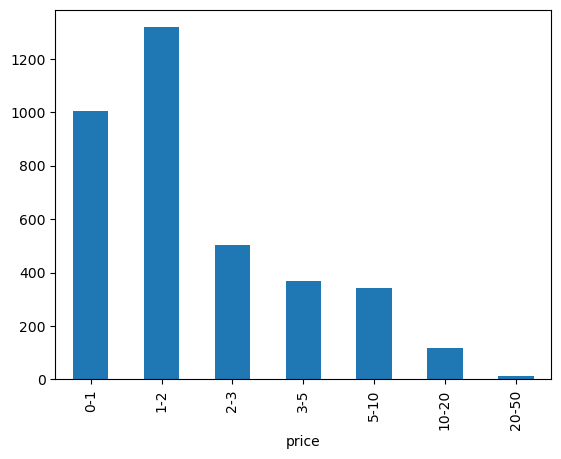

In [70]:
# price binning
bins = [0, 1, 2, 3, 5, 10, 20, 50]
bin_labels = ["0-1", "1-2", "2-3", "3-5", "5-10", "10-20", "20-50"]
pd.cut(df['price'], bins=bins, labels=bin_labels, right=False).value_counts().sort_index().plot(kind='bar')

The majority of properties are priced in the "1-2 crores" and "2-3 crores" ranges.

There's a significant drop in the number of properties priced above "5 crores."

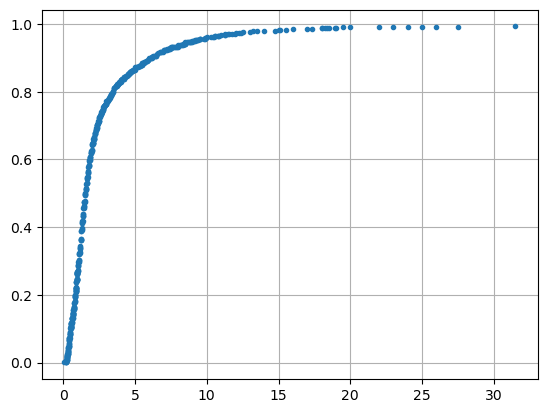

In [74]:
# ecdf plot
ecdf = df['price'].value_counts().sort_index().cumsum() / len(df['price'])
plt.plot(ecdf.index, ecdf, marker='.', linestyle='none')
plt.grid()

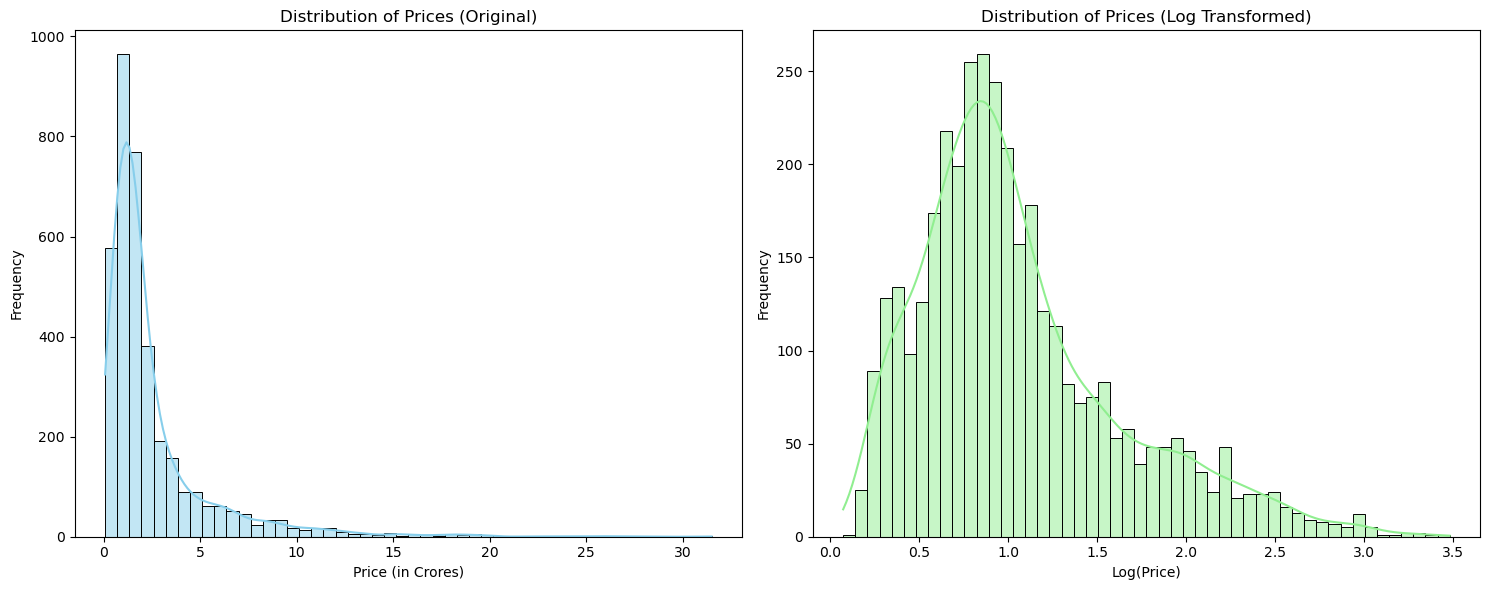

In [76]:
plt.figure(figsize=(15, 6))

# Distribution plot without log transformation
plt.subplot(1, 2, 1)
sns.histplot(df['price'], kde=True, bins=50, color='skyblue')
plt.title('Distribution of Prices (Original)')
plt.xlabel('Price (in Crores)')
plt.ylabel('Frequency')

# Distribution plot with log transformation
plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['price']), kde=True, bins=50, color='lightgreen')
plt.title('Distribution of Prices (Log Transformed)')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

np.log1p(x): This function computes the natural logarithm of 1+x. It's designed to provide more accurate results for values of x that are very close to zero.

Using np.log1p helps in transforming the price column while ensuring that any value (including zero, if present) is handled appropriately. When we need to reverse the transformation, we can use np.expm1 which computes e^x-1

In [80]:
skewness = np.log1p(df['price']).skew()
kurtosis = np.log1p(df['price']).kurt()

print(skewness,kurtosis)

1.0762515290866759 0.9703962690038179


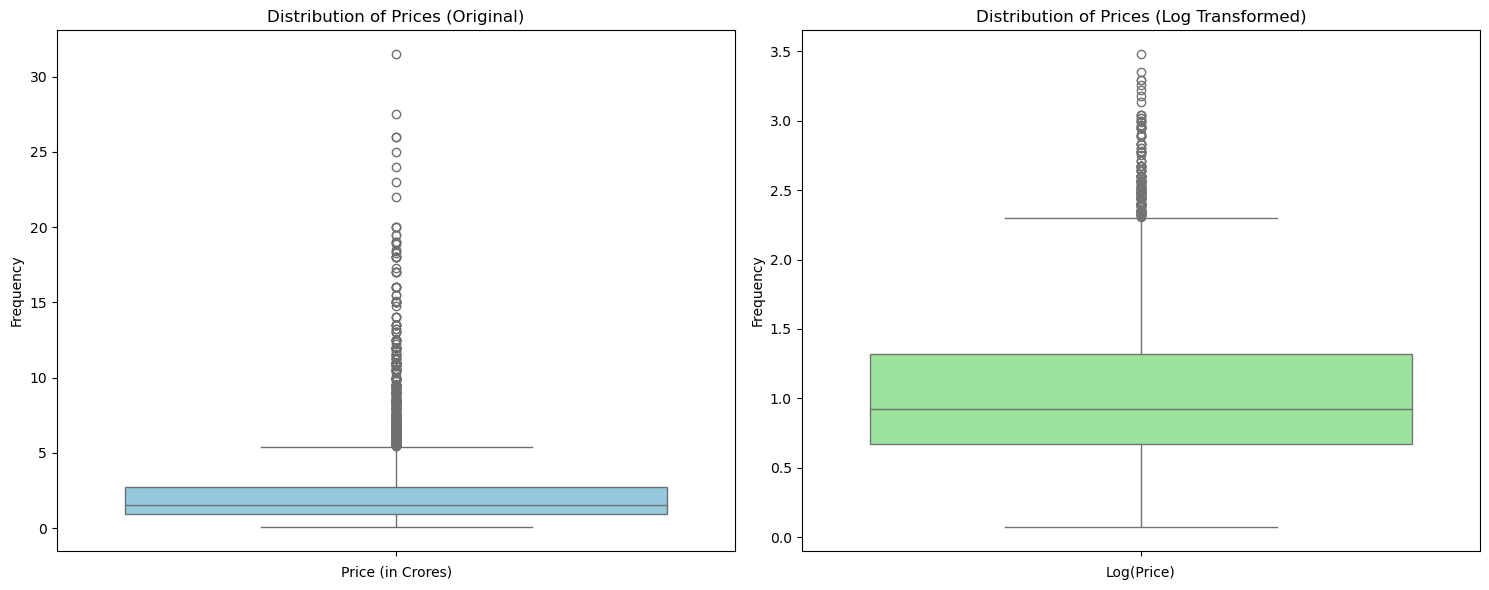

In [82]:
plt.figure(figsize=(15, 6))

# Distribution plot without log transformation
plt.subplot(1, 2, 1)
sns.boxplot(df['price'], color='skyblue')
plt.title('Distribution of Prices (Original)')
plt.xlabel('Price (in Crores)')
plt.ylabel('Frequency')

# Distribution plot with log transformation
plt.subplot(1, 2, 2)
sns.boxplot(np.log1p(df['price']), color='lightgreen')
plt.title('Distribution of Prices (Log Transformed)')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

price_per_sqft

In [85]:
df['price_per_sqft'].isnull().sum()

26

In [87]:
df['price_per_sqft'].describe()

count      3666.000000
mean      13901.355701
std       23214.114343
min           4.000000
25%        6818.000000
50%        9020.000000
75%       13877.250000
max      600000.000000
Name: price_per_sqft, dtype: float64

<Axes: xlabel='price_per_sqft', ylabel='Count'>

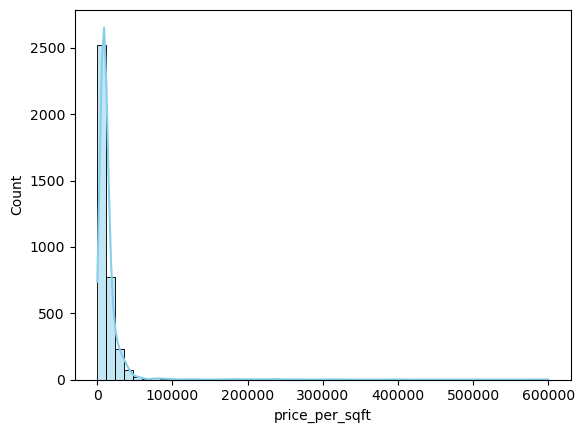

In [89]:
sns.histplot(df['price_per_sqft'], bins=50, color='skyblue', kde=True)

Most properties have a price_per_sqft ranging between approximately ₹0 and ₹40,000. There is a significant concentration in the lower range, with a few properties having exceptionally high price_per_sqft.

<Axes: ylabel='price_per_sqft'>

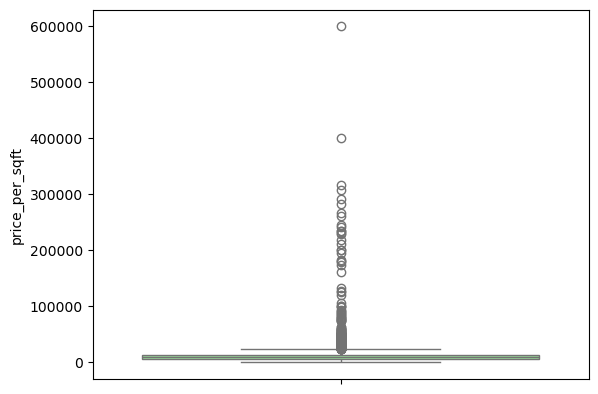

In [92]:
sns.boxplot(df['price_per_sqft'], color='lightgreen')

The box plot clearly shows several outliers, especially on the higher side. The interquartile range (IQR) is relatively compact, but there are many data points beyond the "whiskers" of the box plot, indicating potential outliers

Observations

Potential Outliers
Right Skewed
17 missing values

bedRoom

In [99]:
df['bedRoom'].isnull().sum()

0

<Axes: xlabel='bedRoom'>

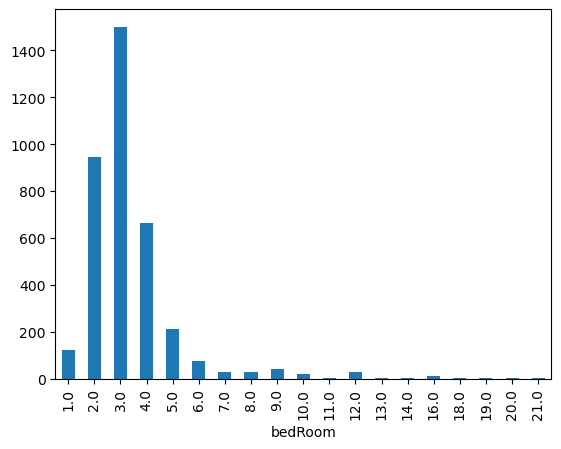

In [101]:
df['bedRoom'].value_counts().sort_index().plot(kind='bar')

<Axes: ylabel='proportion'>

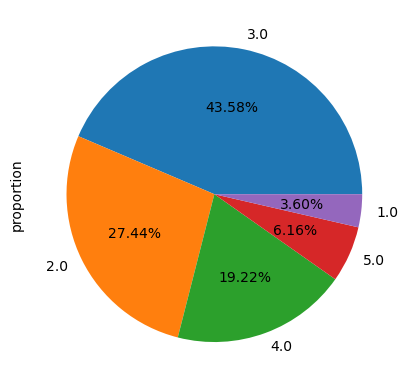

In [103]:
df['bedRoom'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

bathroom

In [106]:
df['bathroom'].isnull().sum()

0

<Axes: xlabel='bathroom'>

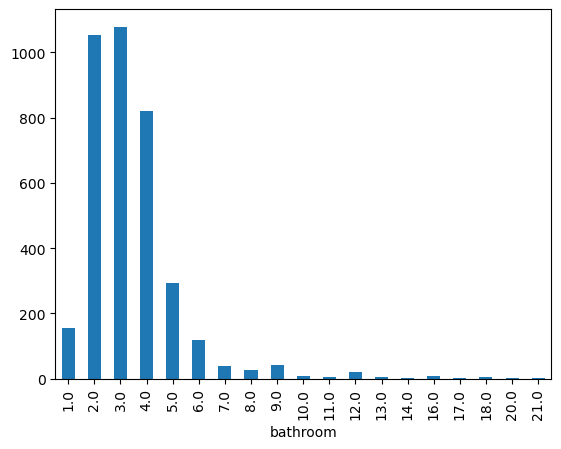

In [108]:
df['bathroom'].value_counts().sort_index().plot(kind='bar')

<Axes: ylabel='proportion'>

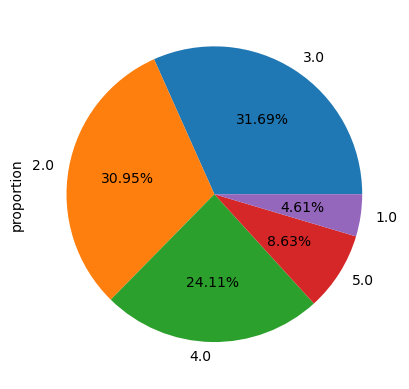

In [110]:
df['bathroom'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

In [112]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,...,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,adani oyster greens,sector 102,1.90,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,...,NaN,NaN,1889.0,1,0,1,1,0,0,0
1,flat,ramprastha city,dwarka expressway,1.30,9027.0,1440.0,Super Built up area 1440(133.78 sq.m.),3.0,3.0,2,...,1440.0,NaN,NaN,0,0,0,0,0,0,0
2,flat,assotech blith,sector 99,0.92,6739.0,1365.0,Super Built up area 1365(126.81 sq.m.),2.0,2.0,3+,...,1365.0,NaN,NaN,0,0,0,0,0,0,56
3,flat,aipl the peaceful homes,sector 70a,2.80,11914.0,2350.0,Super Built up area 2350(218.32 sq.m.)Carpet a...,3.0,4.0,3,...,2350.0,NaN,1322.0,0,1,0,0,0,0,49
4,flat,gls avenue 51,sector 92,0.42,7106.0,591.0,Carpet area: 591 (54.91 sq.m.),2.0,2.0,1,...,NaN,NaN,591.0,1,0,0,1,0,2,42


balcony

In [115]:
df['balcony'].isnull().sum()


0

<Axes: xlabel='balcony'>

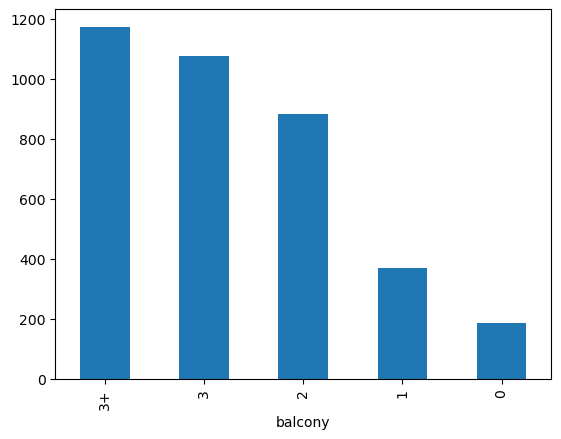

In [119]:
df['balcony'].value_counts().plot(kind='bar')

<Axes: ylabel='proportion'>

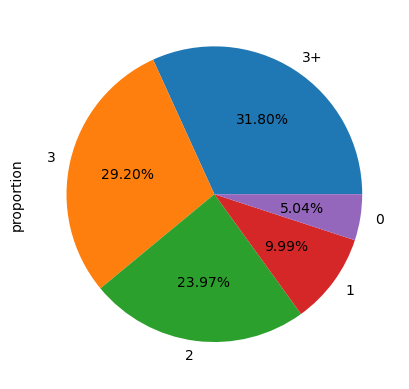

In [121]:
df['balcony'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

floorNum

In [124]:
df.iloc[:,10:].head()

,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,9.0,North-East,Relatively New,NaN,NaN,1889.0,1,0,1,1,0,0,0
1,3.0,NaN,Under Construction,1440.0,NaN,NaN,0,0,0,0,0,0,0
2,22.0,NaN,Under Construction,1365.0,NaN,NaN,0,0,0,0,0,0,56
3,22.0,North-East,Relatively New,2350.0,NaN,1322.0,0,1,0,0,0,0,49
4,4.0,East,Relatively New,NaN,NaN,591.0,1,0,0,1,0,2,42


In [126]:
df['floorNum'].isnull().sum()

19

In [128]:
df['floorNum'].describe()

count    3673.000000
mean        6.782739
std         6.006909
min         0.000000
25%         2.000000
50%         5.000000
75%        10.000000
max        51.000000
Name: floorNum, dtype: float64

<Axes: xlabel='floorNum'>

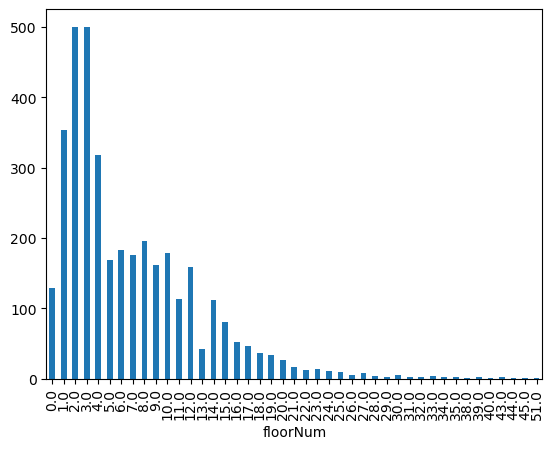

In [130]:
df['floorNum'].value_counts().sort_index().plot(kind='bar')

<Axes: ylabel='floorNum'>

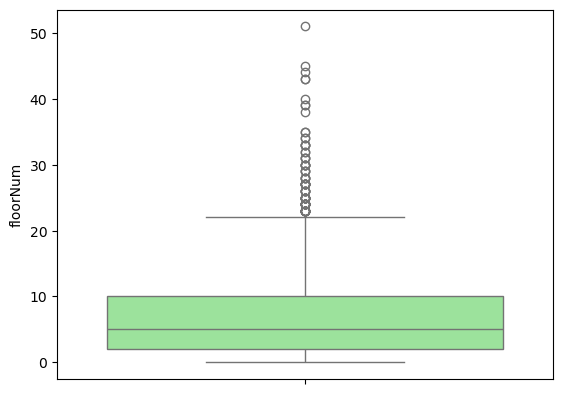

In [132]:
sns.boxplot(df['floorNum'], color='lightgreen')

The majority of the properties lie between the ground floor (0) and the 25th floor.
Floors 1 to 4 are particularly common, with the 3rd floor being the most frequent.
There are a few properties located at higher floors, but their frequency is much lower.
The box plot reveals that the majority of the properties are concentrated around the lower floors. The interquartile range (IQR) lies between approximately the 2nd and 10th floors.
Data points beyond the "whiskers" of the box plot, especially on the higher side, indicate potential outliers.
facing

facing

In [135]:
df['facing'].isnull().sum()
1045

1045

In [137]:
df['facing'].fillna('NA',inplace=True)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8120\3692945726.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['facing'].fillna('NA',inplace=True)


In [139]:
df['facing'].value_counts()

facing
NA            1057
North-East     625
East           623
North          388
West           249
South          231
North-West     193
South-East     173
South-West     153
Name: count, dtype: int64

agePossession

In [142]:
df['agePossession'].isnull().sum()

0

In [144]:
df['agePossession'].value_counts()

agePossession
Relatively New        1647
New Property           595
Moderately Old         566
Undefined              446
Old Property           304
Under Construction     134
Name: count, dtype: int64

areas

In [148]:
# super built up area
df['super_built_up_area'].isnull().sum()

1816

In [150]:
df['super_built_up_area'].describe()

count     1876.000000
mean      1925.371295
std        763.990307
min         89.000000
25%       1479.750000
50%       1828.000000
75%       2215.000000
max      10000.000000
Name: super_built_up_area, dtype: float64

<Axes: xlabel='super_built_up_area', ylabel='Count'>

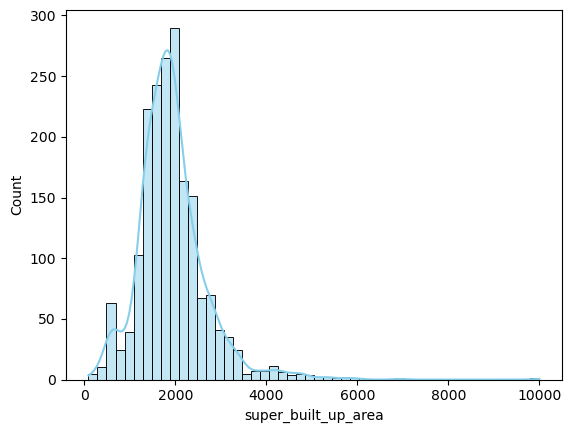

In [152]:
sns.histplot(df['super_built_up_area'].dropna(), bins=50, color='skyblue', kde=True)

<Axes: ylabel='super_built_up_area'>

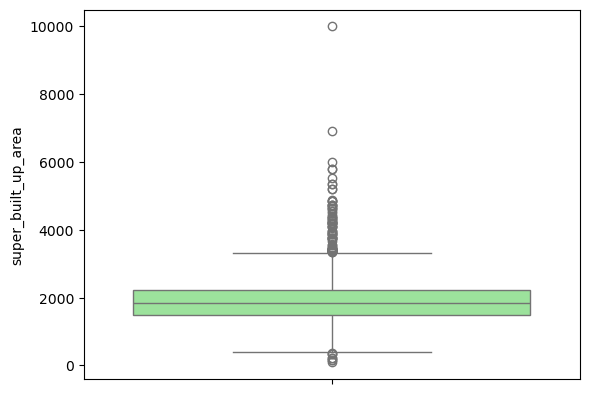

In [154]:
sns.boxplot(df['super_built_up_area'].dropna(), color='lightgreen')

Most properties have a super built-up area ranging between approximately 1,000 sq.ft and 2,500 sq.ft.
There are a few properties with a significantly larger area, leading to a right-skewed distribution.
The interquartile range (IQR) lies between roughly 1,480 sq.ft and 2,215 sq.ft, indicating that the middle 50% of the properties fall within this range.
There are several data points beyond the upper "whisker" of the box plot, indicating potential outliers. These are properties with an unusually large super built-up area.

In [156]:
# built up area
df['built_up_area'].isnull().sum()

1991

In [158]:
df['built_up_area'].describe()

count      1701.000000
mean       2370.877736
std       17885.131480
min           2.000000
25%        1100.000000
50%        1650.000000
75%        2400.000000
max      737147.000000
Name: built_up_area, dtype: float64

<Axes: xlabel='built_up_area', ylabel='Count'>

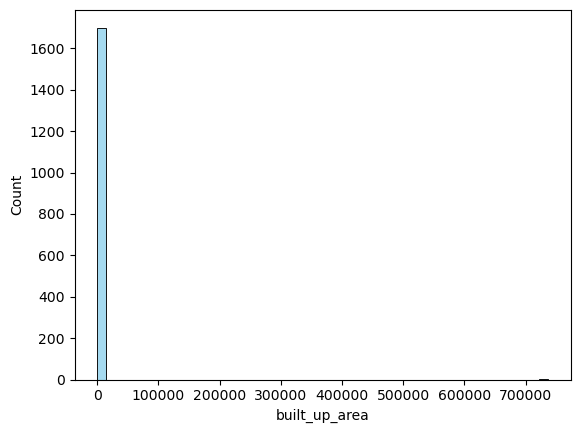

In [161]:
sns.histplot(df['built_up_area'].dropna(), bins=50, color='skyblue', kde=False)

<Axes: ylabel='built_up_area'>

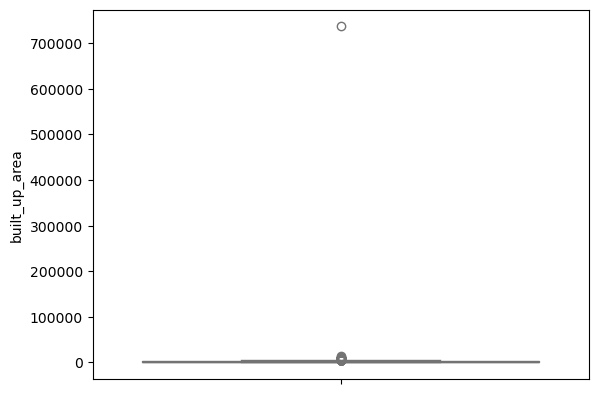

In [163]:
sns.boxplot(df['built_up_area'].dropna(), color='lightgreen')

Most properties have a built-up area ranging roughly between 500 sq.ft and 3,500 sq.ft.
There are very few properties with a much larger built-up area, leading to a highly right-skewed distribution.
The box plot confirms the presence of significant outliers on the higher side. The data's interquartile range (IQR) is relatively compact, but the "whiskers" of the box plot are stretched due to the outliers.

The presence of extreme values, especially on the higher side, suggests that there may be outliers or data errors. This could also be due to some properties being exceptionally large, like a commercial complex or an entire building being listed.

In [166]:
# carpet area
df['carpet_area'].isnull().sum()

1815

In [168]:
df['carpet_area'].describe()

count      1877.000000
mean       2525.787447
std       22769.546460
min          15.000000
25%         845.000000
50%        1300.000000
75%        1790.000000
max      607936.000000
Name: carpet_area, dtype: float64

<Axes: xlabel='carpet_area', ylabel='Count'>

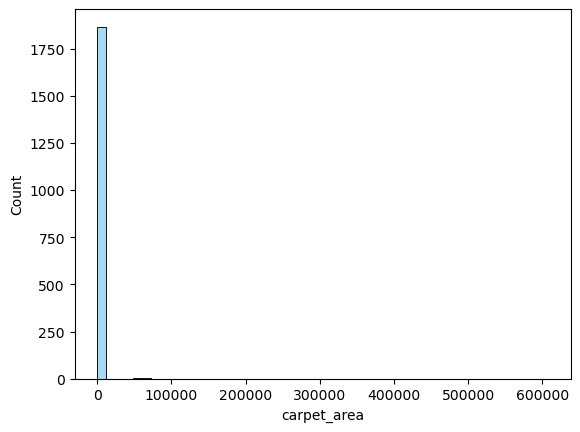

In [170]:
sns.histplot(df['carpet_area'].dropna(), bins=50, color='skyblue', kde=False)

<Axes: ylabel='carpet_area'>

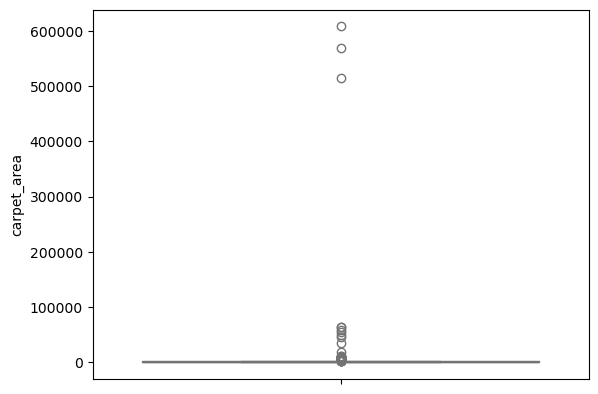

In [172]:
sns.boxplot(df['carpet_area'].dropna(), color='lightgreen')

In [174]:
df.iloc[:,16:]

,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,1,0,1,1,0,0,0
1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,56
3,0,1,0,0,0,0,49
4,1,0,0,1,0,2,42
...,...,...,...,...,...,...,...
3809,0,0,0,0,0,2,174
3811,0,0,0,0,0,0,59
3812,0,0,0,1,0,2,156
3813,0,1,0,0,0,0,38


additional rooms

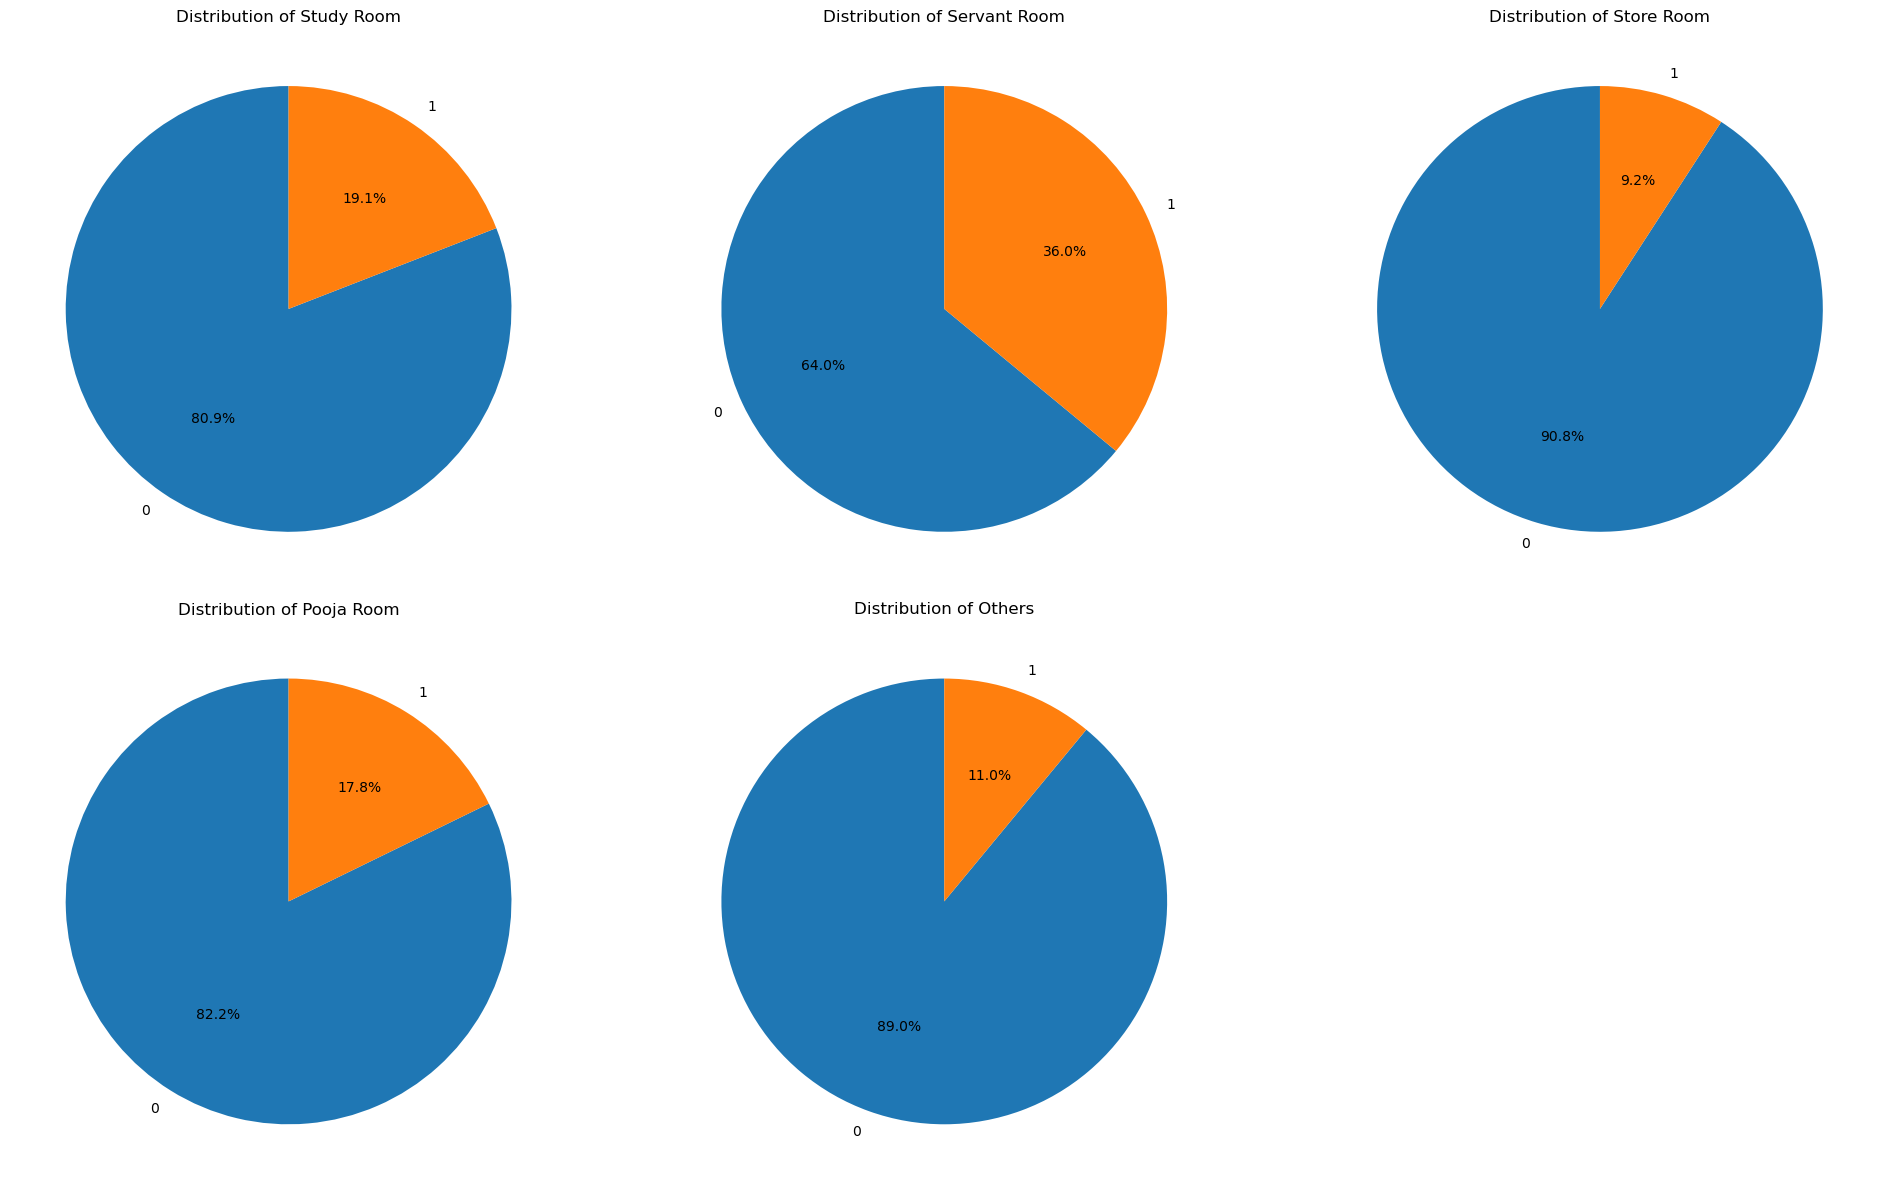

In [179]:
plt.figure(figsize=(20, 12))

# Create a subplot of pie charts for each room type
for idx, room in enumerate(['study room','servant room','store room','pooja room','others'], 1):
    ax = plt.subplot(2, 3, idx)
    df[room].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, ax=ax)
    plt.title(f'Distribution of {room.title()}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

furnishing_type

In [182]:
df['furnishing_type'].value_counts()

furnishing_type
0    2433
2    1052
1     207
Name: count, dtype: int64

<Axes: ylabel='count'>

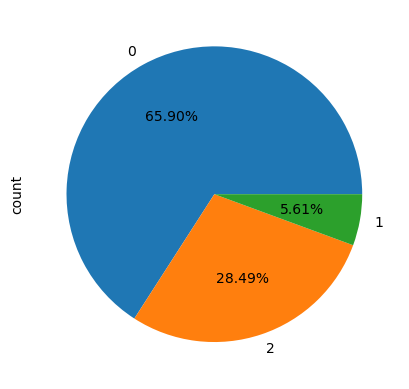

In [184]:
df['furnishing_type'].value_counts().plot(kind='pie',autopct='%0.2f%%')

luxury score

In [187]:
df['luxury_score'].isnull().sum()

0

In [189]:
df['luxury_score'].describe()

count    3692.000000
mean       71.260293
std        53.115239
min         0.000000
25%        31.000000
50%        58.000000
75%       110.000000
max       174.000000
Name: luxury_score, dtype: float64

<Axes: xlabel='luxury_score', ylabel='Count'>

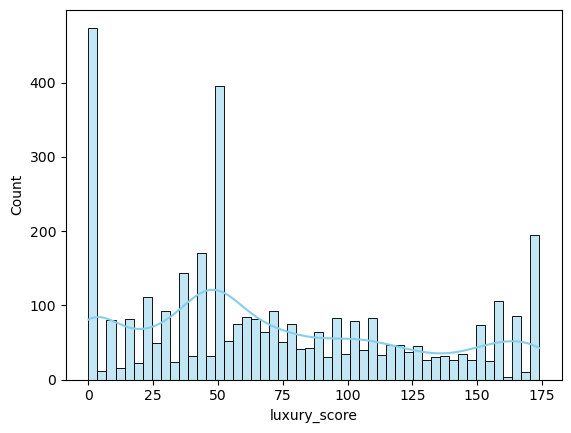

In [191]:
sns.histplot(df['luxury_score'], bins=50, color='skyblue', kde=True)

<Axes: ylabel='luxury_score'>

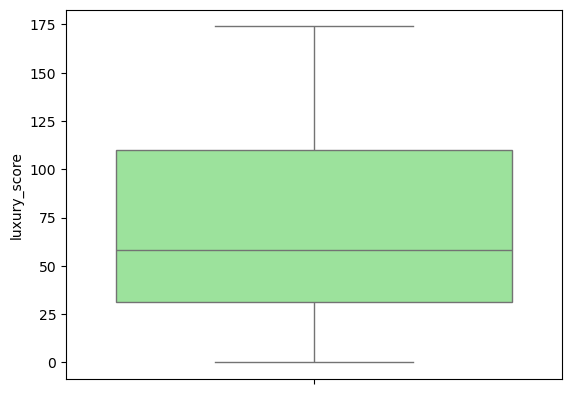

In [193]:
sns.boxplot(df['luxury_score'], color='lightgreen')

The luxury score distribution has multiple peaks, suggesting a multi-modal distribution. There's a significant number of properties with lower luxury scores (around 0-50), and another peak is observed around the 110-130 range.

The box plot reveals that the majority of the properties have luxury scores between approximately 30 and 110. The interquartile range (IQR) lies between these values.

In [196]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,...,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,adani oyster greens,sector 102,1.90,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,...,NaN,NaN,1889.0,1,0,1,1,0,0,0
1,flat,ramprastha city,dwarka expressway,1.30,9027.0,1440.0,Super Built up area 1440(133.78 sq.m.),3.0,3.0,2,...,1440.0,NaN,NaN,0,0,0,0,0,0,0
2,flat,assotech blith,sector 99,0.92,6739.0,1365.0,Super Built up area 1365(126.81 sq.m.),2.0,2.0,3+,...,1365.0,NaN,NaN,0,0,0,0,0,0,56
3,flat,aipl the peaceful homes,sector 70a,2.80,11914.0,2350.0,Super Built up area 2350(218.32 sq.m.)Carpet a...,3.0,4.0,3,...,2350.0,NaN,1322.0,0,1,0,0,0,0,49
4,flat,gls avenue 51,sector 92,0.42,7106.0,591.0,Carpet area: 591 (54.91 sq.m.),2.0,2.0,1,...,NaN,NaN,591.0,1,0,0,1,0,2,42
